# 04 · Report
Collects every `results/*.json`, prints the summary table, and saves figures + `summary.md`
into the results folder (copy that folder into the repo's `results/`).

## 0. Setup
Runtime → Change runtime type → **GPU** (T4 is enough; L4/A100 are faster). Results and the tokenized data are cached on Google Drive (`USE_DRIVE=True`) so the notebooks can share them; set it to `False` to keep everything in `/content`.

In [1]:
import os, sys
USE_DRIVE = os.environ.get("REVLLM_USE_DRIVE", "1") == "1"   # persist data + results on Google Drive
SMOKE = os.environ.get("REVLLM_SMOKE", "0") == "1"   # True = tiny end-to-end pipeline check (~2 min)

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK = "/content/drive/MyDrive/revllm-50m"
else:
    WORK = os.path.abspath("work")
os.makedirs(WORK, exist_ok=True)
DATA_DIR, RES_DIR = f"{WORK}/data", f"{WORK}/results"
print("work dir:", WORK)
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv
!pip -q install tokenizers datasets

work dir: /home/claude/scratch/rep/work
/bin/bash: line 1: nvidia-smi: command not found


In [2]:
import json, glob, os, pandas as pd, matplotlib.pyplot as plt
os.makedirs(f"{RES_DIR}/figs", exist_ok=True)
load = lambda n: json.load(open(f"{RES_DIR}/{n}.json")) if os.path.exists(f"{RES_DIR}/{n}.json") else None
rnd = lambda v, n: None if v is None else round(v, n)
main = [r for r in (load("01_baseline_b32"), load("02_reversible_b32"), load("03_reversible_bmax"), load("03b_reversible_bmax_lr1e-3")) if r]
rows = [{"run": r["run_name"], "mode": r["model"]["mode"], "batch": r["train"]["batch_size"],
         "tokens/step": r["tokens_per_step"], "steps": r["steps"], "peak LR": r["train"]["lr"],
         "final train loss": rnd(r["final_train_loss"], 4), "final val loss": rnd(r["final_val_loss"], 4),
         "tokens/s": round(r["tokens_per_sec"]), "peak mem alloc (GB)": rnd(r["peak_mem_alloc_gb"], 2),
         "peak mem reserved (GB)": rnd(r["peak_mem_reserved_gb"], 2),
         "activation mem (GB)": rnd(r["activation_mem_gb"], 2), "train time (min)": rnd(r["train_time_s"]/60, 1),
         "GPU": r["hw"]["device"]} for r in main]
df = pd.DataFrame(rows); df

,run,mode,batch,tokens/step,steps,peak LR,final train loss,final val loss,tokens/s,peak mem alloc (GB),peak mem reserved (GB),activation mem (GB),train time (min),GPU
0,01_baseline_b32,standard,32,16384,3052,0.001,1.7695,1.8297,76879,3.24,3.47,2.99,10.8,Tesla T4
1,02_reversible_b32,midpoint,32,16384,3052,0.001,1.8126,1.8712,60537,1.11,1.30,0.86,13.8,Tesla T4
2,03_reversible_bmax,midpoint,944,483328,104,0.003,5.5812,5.6162,53366,14.18,14.39,13.92,15.7,Tesla T4
3,03b_reversible_bmax_lr1e-3,midpoint,936,479232,105,0.001,4.2429,4.1266,51241,14.06,14.42,13.81,16.3,Tesla T4


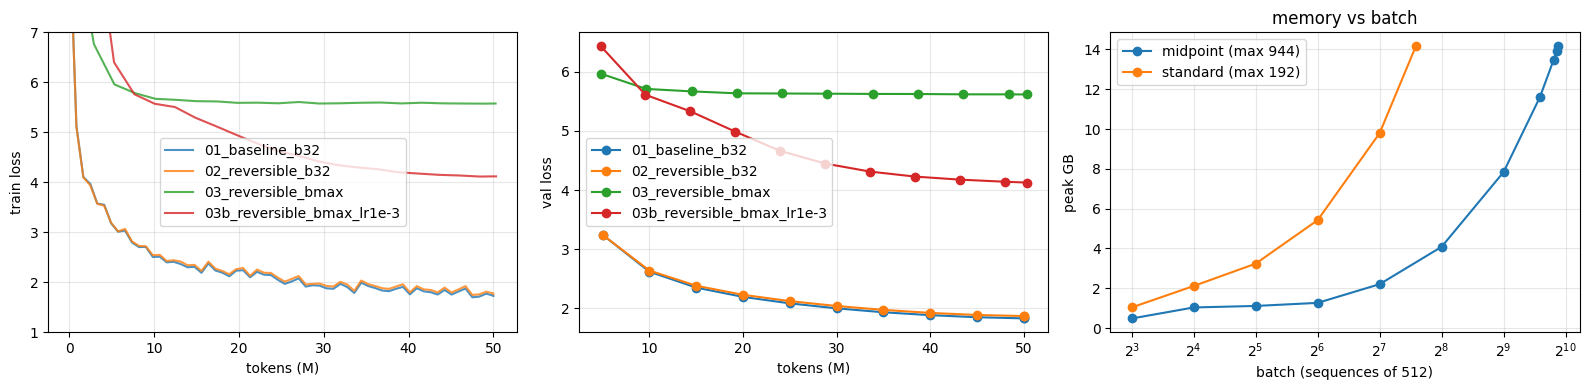

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for r in main:
    h = r["history"]
    ax[0].plot([t/1e6 for t in h["tokens"]], h["loss"], label=r["run_name"], alpha=.8)
    ax[1].plot([t/1e6 for t in h["val_tokens"]], h["val_loss"], "o-", label=r["run_name"])
ax[0].set_ylim(1, 7)
for a, t in zip(ax[:2], ["train loss", "val loss"]):
    a.set_xlabel("tokens (M)"); a.set_ylabel(t); a.grid(alpha=.3); a.legend()
for f in sorted(glob.glob(f"{RES_DIR}/probe_*.json")):
    p = json.load(open(f)); ok = sorted([t for t in p["trace"] if t["ok"]], key=lambda t: t["batch"])
    ax[2].plot([t["batch"] for t in ok], [t["peak_gb"] for t in ok], "o-", label=f"{p['mode']} (max {p['max_batch']})")
ax[2].set_xscale("log", base=2); ax[2].set_xlabel("batch (sequences of 512)"); ax[2].set_ylabel("peak GB")
ax[2].grid(alpha=.3); ax[2].legend(); ax[2].set_title("memory vs batch")
plt.tight_layout(); plt.savefig(f"{RES_DIR}/figs/curves.png", dpi=130); plt.show()

In [4]:
lines = ["| " + " | ".join(df.columns) + " |", "|" + "---|" * len(df.columns)]
lines += ["| " + " | ".join(str(v) for v in row) + " |" for row in df.values]
extra = []
for n in ["probe_standard"] + [os.path.basename(f)[:-5] for f in glob.glob(f"{RES_DIR}/probe_*.json") if "standard" not in f]:
    p = load(n)
    if p: extra.append(f"- {n}: max batch **{p['max_batch']}** ({p['max_tokens_per_step']:,} tok/step), "
                       f"{(p['gb_per_sequence'] or 0)*1024:.1f} MB/sequence, hit probe limit: {p['hit_limit']}")
cv = load("chosen_variant")
if cv:
    extra.append(f"- chosen reversible variant: **{cv['name']}**")
    extra += ["  - bake-off " + json.dumps(b) for b in cv["bakeoff"]]
gc = load("grad_check")
if gc:
    extra += [f"- grad check {g['mode']} it={g['euler_iters']} emb={g['emb_std']}: rel_err={g['rel_err']:.2e}" for g in gc]
samples = [f"**{r['run_name']}**: {r['sample'][:300]!r}" for r in main]
md_txt = "\n".join(lines + [""] + extra + ["", "### Samples", ""] + samples)
open(f"{RES_DIR}/summary.md", "w").write(md_txt); print(md_txt)

| run | mode | batch | tokens/step | steps | peak LR | final train loss | final val loss | tokens/s | peak mem alloc (GB) | peak mem reserved (GB) | activation mem (GB) | train time (min) | GPU |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 01_baseline_b32 | standard | 32 | 16384 | 3052 | 0.001 | 1.7695 | 1.8297 | 76879 | 3.24 | 3.47 | 2.99 | 10.8 | Tesla T4 |
| 02_reversible_b32 | midpoint | 32 | 16384 | 3052 | 0.001 | 1.8126 | 1.8712 | 60537 | 1.11 | 1.3 | 0.86 | 13.8 | Tesla T4 |
| 03_reversible_bmax | midpoint | 944 | 483328 | 104 | 0.003 | 5.5812 | 5.6162 | 53366 | 14.18 | 14.39 | 13.92 | 15.7 | Tesla T4 |
| 03b_reversible_bmax_lr1e-3 | midpoint | 936 | 479232 | 105 | 0.001 | 4.2429 | 4.1266 | 51241 | 14.06 | 14.42 | 13.81 | 16.3 | Tesla T4 |

- probe_standard: max batch **192** (98,304 tok/step), 73.1 MB/sequence, hit probe limit: False
- probe_midpoint: max batch **944** (483,328 tok/step), 15.0 MB/sequence, hit probe limit: False
- chosen reversible variant: **mi

In [5]:
# optional: zip the results folder for download
import shutil; shutil.make_archive(f"{WORK}/results", "zip", RES_DIR)
if IN_COLAB:
    from google.colab import files; files.download(f"{WORK}/results.zip")